In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import pickle
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2026-03-29 19:30:53.414577: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774812653.612947      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774812653.669993      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774812654.173636      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774812654.173668      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774812654.173671      23 computation_placer.cc:177] computation placer alr

In [2]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs:
        print(f"COPY THIS PATH: {os.path.join(root, 'train')}")


COPY THIS PATH: /kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/train


In [3]:
train_dir="/kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/train"

training_set = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    interpolation="bilinear"
)


Found 76515 files belonging to 4 classes.


I0000 00:00:1774812925.509667      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774812925.516022      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [4]:
val_dir="/kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/val"
validation_set = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    interpolation="bilinear"
)


Found 21861 files belonging to 4 classes.


In [5]:
# This uses the CPU to pre-load images so the GPU doesn't have to wait
AUTOTUNE = tf.data.AUTOTUNE
training_set = training_set.prefetch(buffer_size=AUTOTUNE)
validation_set = validation_set.prefetch(buffer_size=AUTOTUNE)


In [6]:
from tensorflow.keras import backend as K
K.clear_session()
# Then re-define and compile your model


In [7]:
import tensorflow as tf
from tensorflow.keras import layers, Model

INPUT_SHAPE=(224,224,3)

base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=INPUT_SHAPE,
    alpha=1.0,
    minimalistic=False,
    include_top=True,
    weights="imagenet",
    input_tensor=None,
    classes=1000,
    pooling=None,
    dropout_rate=0.2,
    classifier_activation="softmax",
    include_preprocessing=True,
    # name="MobileNetV3Large",
)
    

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=INPUT_SHAPE))
model.add(base_model)
model.add(tf.keras.layers.Dense(units = 4,activation='softmax'))
metrics_list = ['accuracy',
                tf.keras.metrics.F1Score()]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=metrics_list
)

model.summary()


22661472/22661472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 1000)           │     5,507,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         4,004 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,511,436 (21.02 MB)

 Trainable params: 5,487,036 (20.93 MB)

 Non-trainable params: 24,400 (95.31 KB)

In [8]:
training_history = model.fit(x=training_set,validation_data=validation_set,epochs=5)

Epoch 1/5


I0000 00:00:1774812960.004756      78 service.cc:152] XLA service 0x7d1680221130 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774812960.004800      78 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774812960.004804      78 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774812964.660023      78 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-03-29 19:36:14.470637: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:36:14.609581: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:36:14.948534: E external/local_xl

2391/2392 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7895 - f1_score: 0.4630 - loss: 1.2235

2026-03-29 19:40:10.837179: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:40:10.971256: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:40:11.273649: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:40:11.410355: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:40:11.846993: E external/local_xla/xla/stream_

2392/2392 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7896 - f1_score: 0.4631 - loss: 1.2234

2026-03-29 19:41:40.063675: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:41:40.197249: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:41:40.504647: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:41:40.642569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:41:40.778877: E external/local_xla/xla/stream_

2392/2392 ━━━━━━━━━━━━━━━━━━━━ 368s 127ms/step - accuracy: 0.7896 - f1_score: 0.4631 - loss: 1.2234 - val_accuracy: 0.8950 - val_f1_score: 0.6908 - val_loss: 0.9519
Epoch 2/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 225s 94ms/step - accuracy: 0.8929 - f1_score: 0.7065 - loss: 0.8893 - val_accuracy: 0.9286 - val_f1_score: 0.8884 - val_loss: 0.7323
Epoch 3/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 222s 93ms/step - accuracy: 0.9513 - f1_score: 0.9171 - loss: 0.6684 - val_accuracy: 0.9564 - val_f1_score: 0.9234 - val_loss: 0.5476
Epoch 4/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 222s 93ms/step - accuracy: 0.9554 - f1_score: 0.9235 - loss: 0.5168 - val_accuracy: 0.9571 - val_f1_score: 0.9269 - val_loss: 0.4350
Epoch 5/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 223s 93ms/step - accuracy: 0.9623 - f1_score: 0.9358 - loss: 0.4020 - val_accuracy: 0.9563 - val_f1_score: 0.9270 - val_loss: 0.3428


In [9]:
# Saving history
with open('training_history.pkl', 'wb') as f:
    pickle.dump(training_history.history, f)
    
#Reloading History from pickle
with open('training_history.pkl', 'rb') as f:
    load_history = pickle.load(f)
load_history

{'accuracy': [0.8342939019203186,
  0.9098607897758484,
  0.9527804851531982,
  0.9558387398719788,
  0.9625301957130432],
 'f1_score': [<tf.Tensor: shape=(4,), dtype=float32, numpy=
  array([8.2976347e-01, 4.9730793e-01, 3.2169826e-04, 9.5938349e-01],
        dtype=float32)>,
  <tf.Tensor: shape=(4,), dtype=float32, numpy=array([0.90361106, 0.90385455, 0.3677902 , 0.97583205], dtype=float32)>,
  <tf.Tensor: shape=(4,), dtype=float32, numpy=array([0.9578969 , 0.92439276, 0.8130015 , 0.9794535 ], dtype=float32)>,
  <tf.Tensor: shape=(4,), dtype=float32, numpy=array([0.95857596, 0.9319009 , 0.8220654 , 0.9825599 ], dtype=float32)>,
  <tf.Tensor: shape=(4,), dtype=float32, numpy=array([0.96660256, 0.94365835, 0.84709793, 0.98398507], dtype=float32)>],
 'loss': [1.1252127885818481,
  0.827749490737915,
  0.6253107786178589,
  0.48632198572158813,
  0.3794841468334198],
 'val_accuracy': [0.8950185179710388,
  0.9286400675773621,
  0.9564064145088196,
  0.9571382999420166,
  0.95631492137908

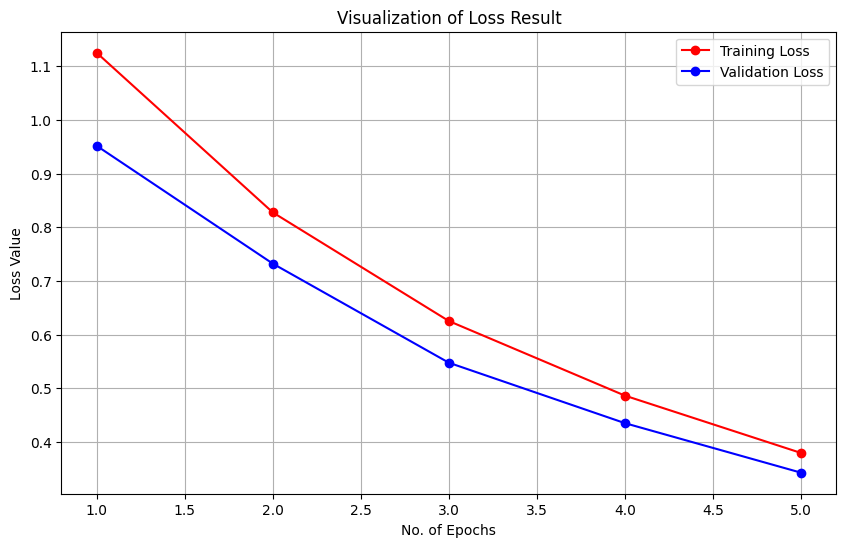

In [10]:
import matplotlib.pyplot as plt

# 1. Automatically get the correct number of epochs from the history data
# This prevents the "mismatch" error
actual_epochs = range(1, len(load_history['loss']) + 1)

# 2. Plotting
plt.figure(figsize=(10, 6))
plt.plot(actual_epochs, load_history['loss'], marker='o', color='red', label='Training Loss')
plt.plot(actual_epochs, load_history['val_loss'], marker='o', color='blue', label='Validation Loss')

# 3. Formatting
plt.xlabel('No. of Epochs')
plt.ylabel('Loss Value')
plt.title('Visualization of Loss Result')
plt.legend()
plt.grid(True) # Adds a grid to make the 99% accuracy easier to see
plt.show()


In [11]:
test_dir="/kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/test"
test_set = validation_set = image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=64,
    image_size=(224, 224),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 10933 files belonging to 4 classes.


In [12]:
test_loss,test_acc,f1_score = model.evaluate(test_set)

2026-03-29 19:56:57.766954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:56:57.919147: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:56:58.313928: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:56:58.454147: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


170/171 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.9550 - f1_score: 0.9254 - loss: 0.3466

2026-03-29 19:57:34.443101: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:57:34.592264: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:57:34.962135: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:57:35.101137: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


171/171 ━━━━━━━━━━━━━━━━━━━━ 49s 215ms/step - accuracy: 0.9550 - f1_score: 0.9254 - loss: 0.3467


Model Evaluation

In [13]:
model.save("Trained_Model.keras")


In [14]:
import os
print(os.listdir('/kaggle/working'))


['Trained_Model.keras', '__notebook__.ipynb', 'training_history.pkl']


In [15]:
model = tf.keras.models.load_model("Trained_Model.keras")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 1000)           │     5,507,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         4,004 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,485,510 (62.89 MB)

 Trainable params: 5,487,036 (20.93 MB)

 Non-trainable params: 24,400 (95.31 KB)

 Optimizer params: 10,974,074 (41.86 MB)

In [16]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# 1. Get all true labels and predictions
y_true = []
y_pred = []

# Loop through the test set to get labels and make predictions
for images, labels in test_set:
    y_true.extend(np.argmax(labels, axis=1))  # Get true class index
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))  # Get predicted class index

# Convert lists to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)


2026-03-29 19:58:26.974858: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:58:27.109913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:58:27.434256: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:58:27.571919: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


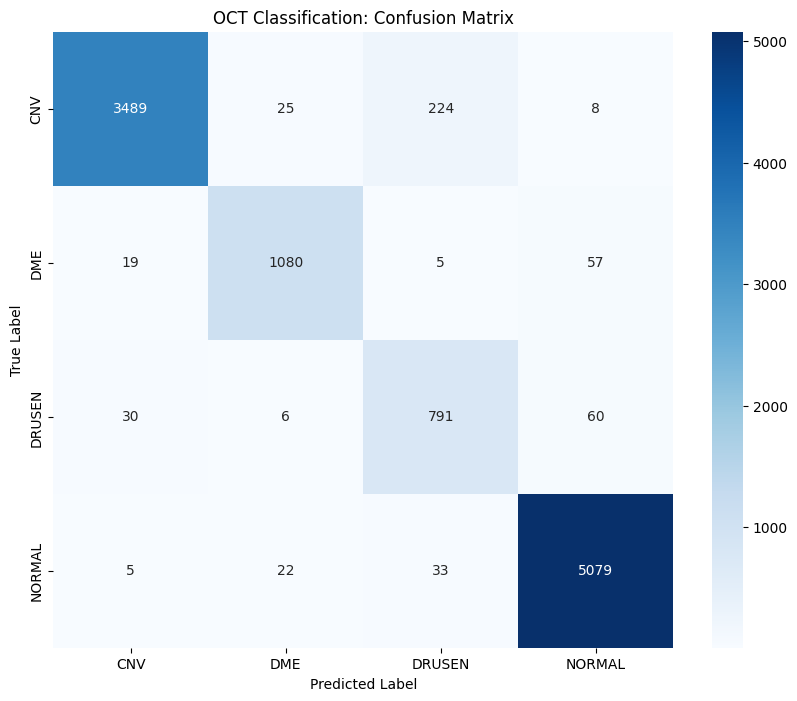

              precision    recall  f1-score   support

         CNV       0.98      0.93      0.96      3746
         DME       0.95      0.93      0.94      1161
      DRUSEN       0.75      0.89      0.82       887
      NORMAL       0.98      0.99      0.98      5139

    accuracy                           0.95     10933
   macro avg       0.92      0.94      0.92     10933
weighted avg       0.96      0.95      0.96     10933



In [17]:
# 2. Define class names (usually: ['CNV', 'DME', 'DRUSEN', 'NORMAL'])
class_names = test_set.class_names

# 3. Create the matrix
cm = confusion_matrix(y_true, y_pred)

# 4. Plot using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('OCT Classification: Confusion Matrix')
plt.show()

# 5. Print a detailed report (Precision, Recall, F1-Score)
print(classification_report(y_true, y_pred, target_names=class_names))


MODEL PREDICTION

In [18]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
import numpy as np
import os

In [19]:
model = tf.keras.models.load_model("Trained_Model.keras")

2026-03-29 19:58:44.864104: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-29 19:58:44.998222: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


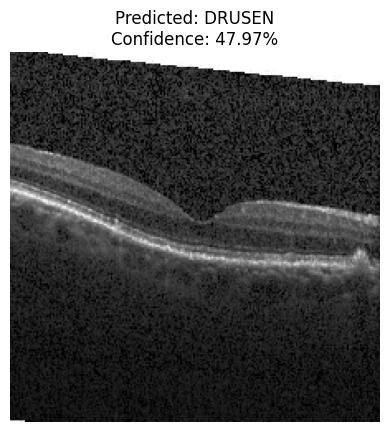

Full Breakdown:
CNV: 24.49%
DME: 7.52%
DRUSEN: 47.97%
NORMAL: 20.01%


In [20]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Path to your image
image_path = '/kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/test/DRUSEN/DRUSEN-1001666-7.jpeg'

def predict_single_image(path, model, test_set):
    # 2. Load and resize (Same as before)
    img = tf.keras.utils.load_img(path, target_size=(224, 224))
    
    # 3. Convert to array (IMPORTANT: Removed the / 255.0 to match your working version)
    img_array = tf.keras.utils.img_to_array(img)
    
    # 4. Add batch dimension
    img_array = tf.expand_dims(img_array, 0)
    
    # 5. Predict
    predictions = model.predict(img_array)
    
    # 6. Extract results correctly
    # We use [0] because the model returns a list of lists: [[prob1, prob2, ...]]
    score_array = predictions[0] 
    
    # Get the names directly from your test_set to ensure the order is perfect
    class_names = test_set.class_names
    
    predicted_index = np.argmax(score_array)
    result = class_names[predicted_index]
    confidence = 100 * score_array[predicted_index]
    
    # 7. Show the result
    plt.imshow(img)
    plt.title(f"Predicted: {result}\nConfidence: {confidence:.2f}%")
    plt.axis('off')
    plt.show()
    
    # Print all probabilities for debugging
    print("Full Breakdown:")
    for name, prob in zip(class_names, score_array):
        print(f"{name}: {prob*100:.2f}%")

# Run the function (Pass 'test_set' so it can get the class names)
predict_single_image(image_path, model, test_set)


**PROBABAILITY CODE**

In [21]:
import numpy as np
from tensorflow.keras.preprocessing import image

# 1. Provide the path to the image you want to test
img_path = "/kaggle/input/datasets/anirudhcv/labeled-optical-coherence-tomography-oct/Dataset - train+val+test/test/NORMAL/NORMAL-1014193-6.jpeg"
# 2. Convert the image into a format the model understands (img_array)
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) # This creates the 'img_array' you were missing

# 3. Predict and show probabilities
predictions = model.predict(img_array)
class_names = test_set.class_names 

print("Probabilities:")
for name, prob in zip(class_names, predictions[0]):
    # Multiply by 100 to get a percentage
    print(f"{name}: {prob*100:.2f}%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Probabilities:
CNV: 7.57%
DME: 3.97%
DRUSEN: 3.67%
NORMAL: 84.79%
